In [80]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import scipy.stats as stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [81]:
df =pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/train.csv',usecols=['Age', 'Fare', 'Survived'])
df['Age'].fillna(df['Age'].mean(), inplace=True)

/var/folders/lh/42glnkrn40x_dxrvypysh9w00000gn/T/ipykernel_64333/759493297.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].mean(), inplace=True)


In [82]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [83]:
X = df.iloc[:,1:3]
y = df.iloc[:,0]

In [84]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

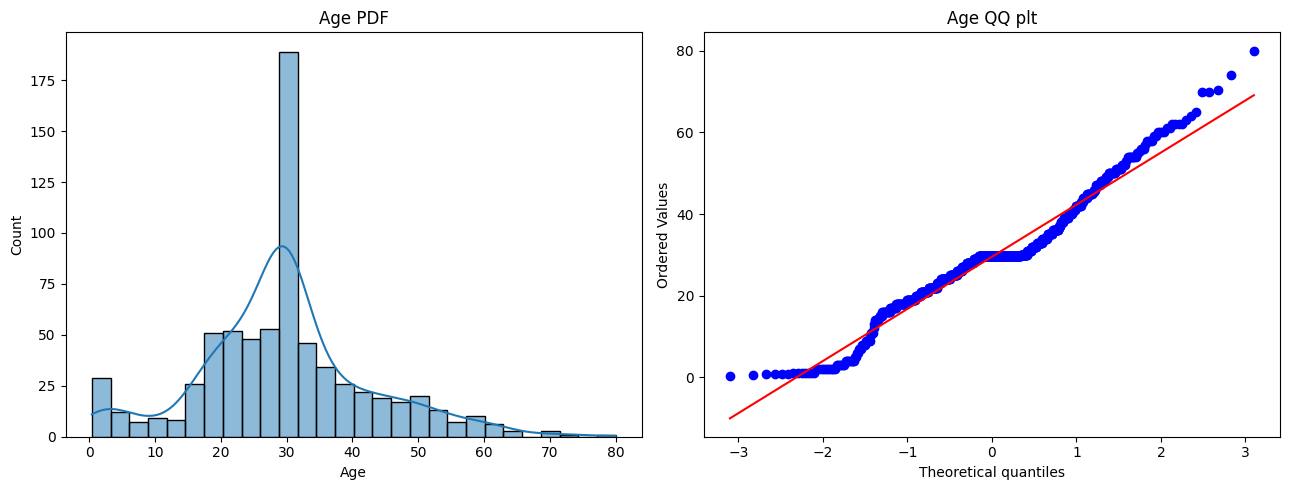

In [85]:
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)
sns.histplot(X_train['Age'], kde=True)
plt.title('Age PDF')


plt.subplot(1,2,2)
stats.probplot(X_train['Age'], dist='norm',plot=plt)
plt.title('Age QQ plt')

plt.tight_layout()
plt.show()

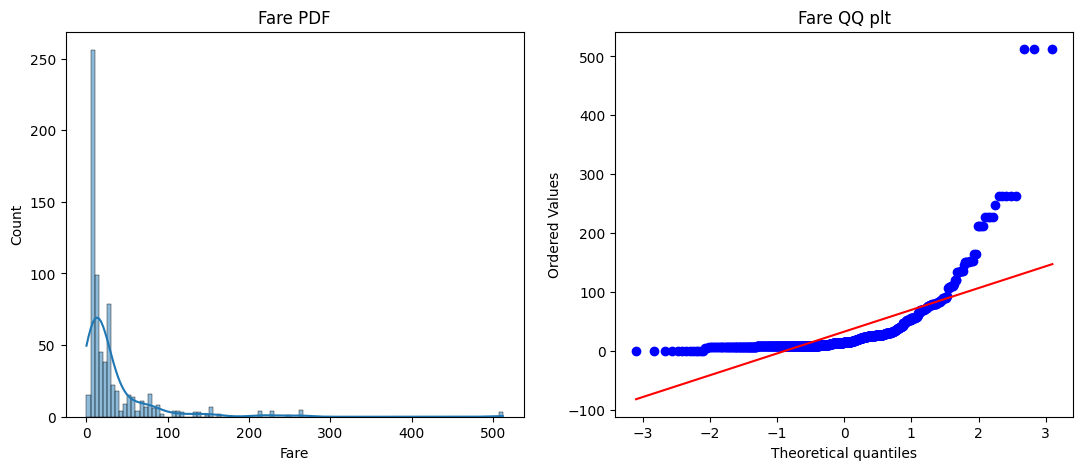

In [86]:
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)
sns.histplot(X_train['Fare'], kde=True)
plt.title('Fare PDF')

plt.subplot(1,2,2)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare QQ plt')

plt.show()

In [87]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [88]:
clf.fit(X_train,y_train)
clf2.fit(X_train,y_train)

DecisionTreeClassifier()

In [89]:
y_pred = clf.predict(X_test)
y_pred2 = clf2.predict(X_test)

In [90]:
print('accuracy LR -> ', accuracy_score(y_test,y_pred))
print('accuracy DTC -> ', accuracy_score(y_test,y_pred2))

accuracy LR ->  0.6480446927374302
accuracy DTC ->  0.664804469273743


In [91]:
trf = FunctionTransformer(func=np.log1p)

In [92]:
X_train_transform = trf.fit_transform(X_train)
X_test_transform = trf.transform(X_test)

In [93]:
clf = LogisticRegression()
clf1 = DecisionTreeClassifier()

In [94]:
clf.fit(X_train_transform,y_train)
clf1.fit(X_train_transform,y_train)

DecisionTreeClassifier()

In [95]:
y_pred_transform = clf.predict(X_test_transform)
y_pred_transform1 = clf1.predict(X_test_transform)

In [96]:
print('Accuracy LR ->', accuracy_score(y_test,y_pred_transform))
print('Accuracy DTC ->', accuracy_score(y_test,y_pred_transform1))

Accuracy LR -> 0.6815642458100558
Accuracy DTC -> 0.6759776536312849


In [97]:
X_transform = trf.fit_transform(X)

In [98]:
clf = LogisticRegression()
clf1 = DecisionTreeClassifier()

In [99]:
print('LR -> ', np.mean(cross_val_score(clf,X_transform,y, scoring='accuracy', cv=10)))
print('DTC -> ', np.mean(cross_val_score(clf1,X_transform,y, scoring='accuracy', cv=10)))

LR ->  0.678027465667915
DTC ->  0.6610736579275905


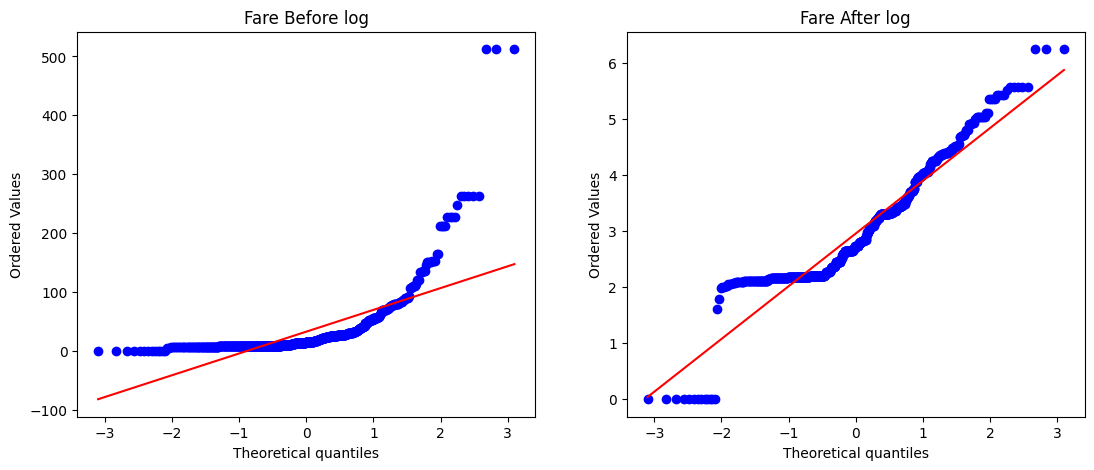

In [100]:
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)
stats.probplot(X_train['Fare'], dist='norm', plot=plt)
plt.title('Fare Before log')

plt.subplot(1,2,2)
stats.probplot(X_train_transform['Fare'], dist='norm', plot=plt)
plt.title('Fare After log')

plt.show()

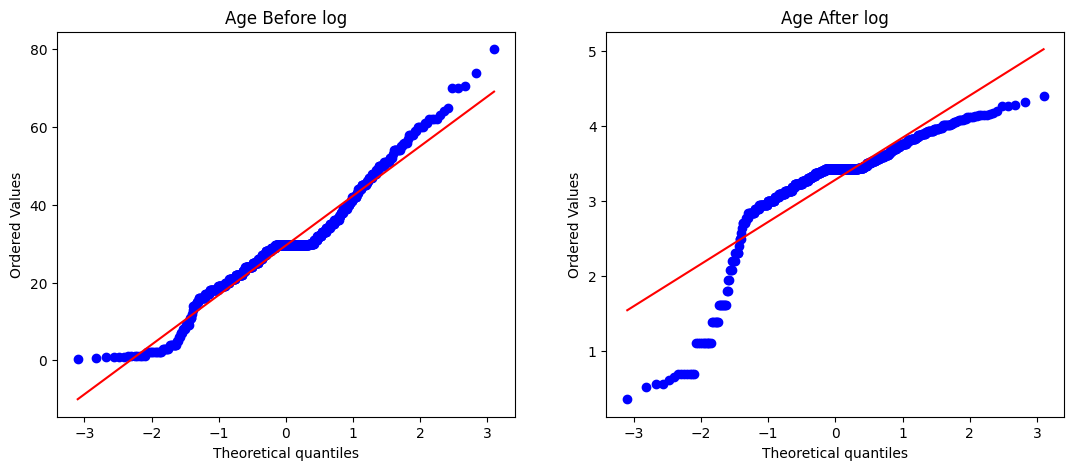

In [101]:
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)
stats.probplot(X_train['Age'], dist='norm', plot=plt)
plt.title('Age Before log')

plt.subplot(1,2,2)
stats.probplot(X_train_transform['Age'], dist='norm', plot=plt)
plt.title('Age After log')

plt.show()

In [111]:
def apply_trasform(transform , fuxn_name= 'transform'):
    X = df.iloc[:,1:3]
    y = df.iloc[:,0]

    trf1 = ColumnTransformer([(fuxn_name,FunctionTransformer(transform),['Fare'])],remainder='passthrough')

    X_transformed = trf1.fit_transform(X)

    clf = LogisticRegression()

    print('Accuracy -> ', np.mean(cross_val_score(clf,X_transformed,y,scoring='accuracy',cv=10)))

    plt.figure(figsize=(13,5))

    plt.subplot(1,2,1)
    stats.probplot(X['Fare'],dist='norm', plot=plt)
    plt.title('Fare QQ plt Before')

    plt.subplot(1,2,2)
    stats.probplot(X_transformed[:,0], dist='norm', plot=plt)
    plt.title('Fare QQ plt After')

    plt.show()

Accuracy ->  0.6589013732833957


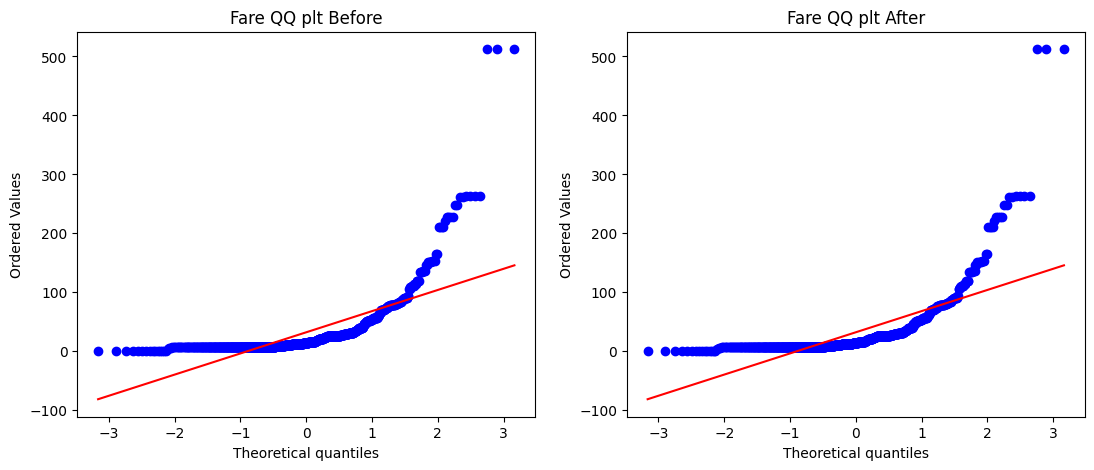

In [116]:
apply_trasform(lambda x: x)

Accuracy ->  0.6431335830212235


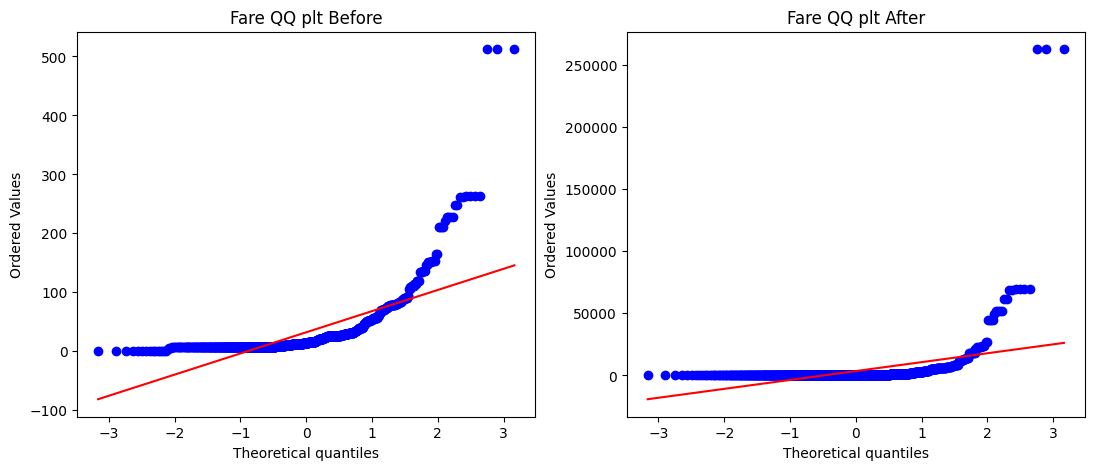

In [115]:
apply_trasform(lambda x: x**2)

Accuracy ->  0.6589013732833957


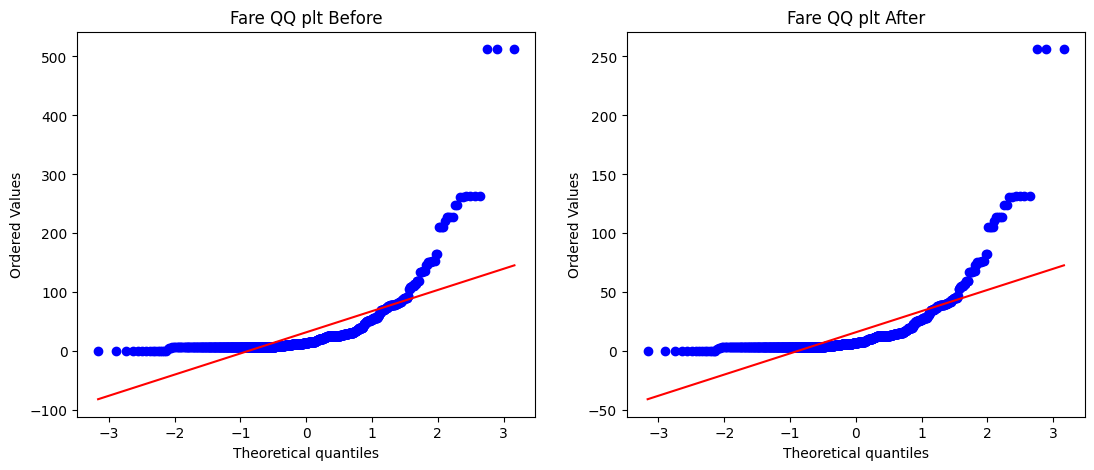

In [114]:
apply_trasform(lambda x: x**1/2)

Accuracy ->  0.61729088639201


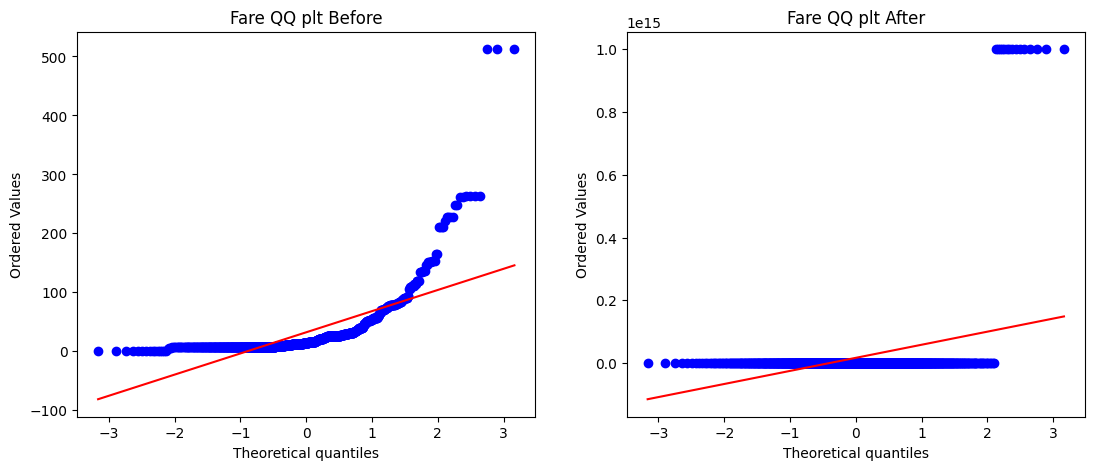

In [113]:
apply_trasform(lambda x: 1/(x+0.000000000000001))

Accuracy ->  0.6712609238451936


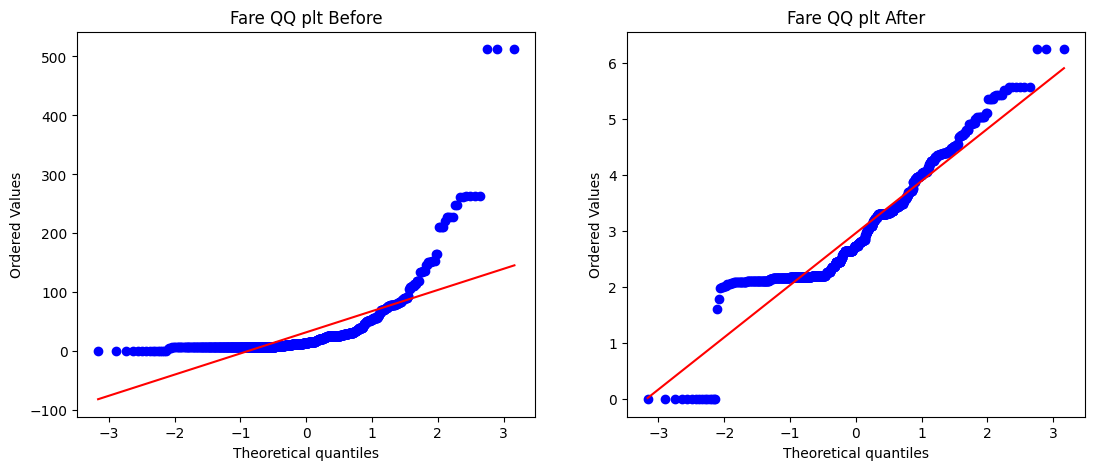

In [112]:
apply_trasform(np.log1p,'log')